# Latent profiles of personality traits

## 1. Research question

How do two and four Gaussian mixture components summarize the same multidimensional trait scores? Can we distinguish broad elevation from profile shape, and what happens to assignment stability when we add components?

**Data provenance.** All data are completely synthetic. The simulation deliberately uses four underlying components for teaching. Every table and figure comes from fictional scores. The four-profile result reflects the simulation design and provides no empirical evidence about personality profiles.

## 2. Why latent profiles?

Trait scores are continuous. A mixture model represents their joint distribution as a weighted combination of component distributions. A component summarizes a pattern of scores with a mean and within-component variability. Each record has a posterior probability of belonging to each component.

A mixture can summarize an overall trait gradient or reveal relative elevations on specific traits. Whether the components correspond to distinct psychological groups requires additional evidence.

## 3. Synthetic data generation

The generator creates 1,000 observations on 25 continuous scores named after PID-5 facets. Each facet is shown once under a display domain to group the plots. The grouping covers supplementary facets for readability and does not implement any PID-5 scoring key.

| Display domain | Facets and abbreviations |
|---|---|
| Negative Affectivity | Anxiousness (Anx), Emotional Lability (EL), Separation Insecurity (SI), Submissiveness (Sub), Hostility (Hos), Perseveration (Pers) |
| Detachment | Withdrawal (With), Anhedonia (Anh), Intimacy Avoidance (IA), Depressivity (Dep), Restricted Affectivity (RA), Suspiciousness (Susp) |
| Antagonism | Manipulativeness (Man), Deceitfulness (Dec), Grandiosity (Gra), Attention Seeking (AS), Callousness (Cal) |
| Disinhibition | Irresponsibility (Irr), Impulsivity (Imp), Distractibility (Distr), Risk Taking (RT), Rigid Perfectionism (RP) |
| Psychoticism | Unusual Beliefs and Experiences (UBE), Eccentricity (Ecc), Perceptual Dysregulation (PD) |

The generator specifies four components by design. The two outer components differ mainly in overall elevation. The two intermediate components have similar overall elevations and opposing facet-specific patterns, including contrasts within domains. For example, the simulated shifts for Hostility and Anxiousness differ in sign within Negative Affectivity. Facets also vary in how strongly they reflect general elevation and in their within-component noise. The continuous scores are fictional and are generated independently within each component.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Support kernels started from either the repository root or notebooks/.
root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if not (root / "src" / "simulation.py").is_file():
    raise FileNotFoundError("Start Jupyter from the repository root or notebooks directory.")
sys.path.insert(0, str(root))

from src.simulation import DOMAINS, FACETS, simulate_facets
from src.modeling import compare_models, describe_profiles, standardize
from src.visualization import plot_profile_lines, plot_profiles, plot_selection, plot_sizes

plt.style.use("seaborn-v0_8-whitegrid")
figure_dir = root / "figures"
figure_dir.mkdir(exist_ok=True)

scores = simulate_facets(seed=314159)
print(f"{len(scores):,} synthetic observations · {len(FACETS)} facets")

1,000 synthetic observations · 25 facets


## 4. Data preparation and standardization

The preparation step checks that every score is finite and that every indicator varies. Standardization centers each synthetic facet and scales it to unit variance, so component means can be compared in standard deviation units. This notebook explores a single synthetic sample and standardizes it before fitting the candidate models.

In [2]:
values = standardize(scores)

## 5. Gaussian Mixture Models

We fit diagonal covariance GMMs with one to eight components. Each component has its own mean and variance for each facet. The diagonal model assumes conditional independence of facets within a component. Each of five fixed seeds runs 12 separate k-means initializations for EM. For each count, the fit with the highest log-likelihood among the converged runs is used for the model summaries.

In [3]:
metrics, models = compare_models(values)
summaries = {k: describe_profiles(models[k], values, FACETS) for k in (2, 4, 6)}

## 6. Comparing candidate solutions

Lower AIC and BIC indicate better penalized fit for this comparison. Relative entropy near one indicates confident assignments under the fitted model. It is undefined for one component. Modal sizes count records by their most probable component, including any empty component when finding the minimum size.

Adjusted Rand index (ARI) compares assignments from the best converged run for each seed pair. ARI of one means identical assignments up to label order. For one component the agreement is trivial and is omitted from the stability plot.

In [4]:
display(metrics.round(3))

,log_likelihood,AIC,BIC,relative_entropy,min_modal_n,max_modal_n,converged_seeds,median_ARI,min_ARI
k,,,,,,,,,
1,-35473.463,71046.927,71292.314,NaN,1000,1000,5,1.000,1.000
2,-30609.324,61420.648,61916.331,0.996,477,523,5,1.000,1.000
3,-28493.744,57291.488,58037.467,0.999,248,475,5,1.000,1.000
4,-26592.897,53591.794,54588.068,1.000,218,277,5,1.000,1.000
5,-26545.258,53598.517,54845.086,0.977,49,258,5,0.854,0.806
6,-26499.741,53609.483,55106.348,0.957,35,277,5,0.815,0.753
7,-26451.856,53615.712,55362.872,0.955,33,247,5,0.752,0.694
8,-26407.197,53628.394,55625.851,0.934,40,258,5,0.638,0.542


## 7. Model fit versus stability

The information criteria balance fit against model size with different penalties. ARI measures agreement between runs on the same sample. Read both alongside convergence, classification certainty and the smallest groups. A high posterior can coexist with sensitivity to initialization.

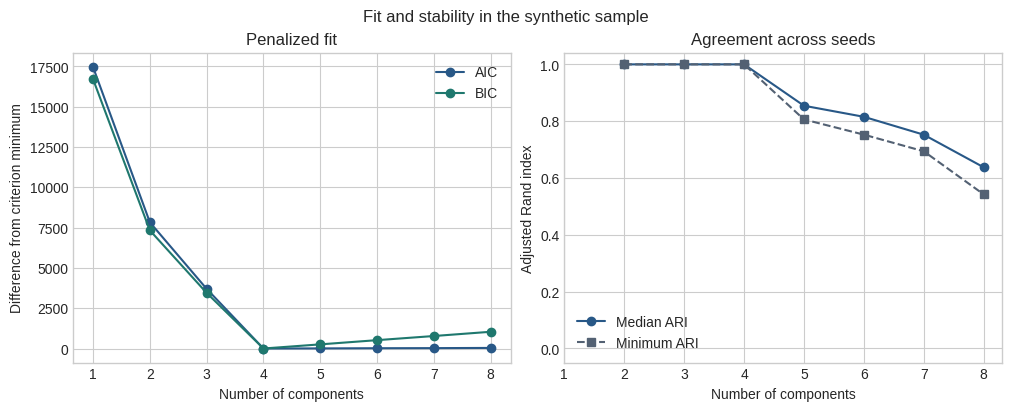

In [5]:
fig = plot_selection(metrics)
fig.savefig(figure_dir / "fit-and-stability.png", dpi=170, bbox_inches="tight")
plt.show()

## 8. General elevation versus profile shape

Each centroid is a vector of 25 fitted means. Its average is its **general elevation**. Subtracting that average from all 25 means leaves its **shape**, the relative emphasis across facets. The heatmaps share a scale within each column. Profiles are ordered by elevation separately for each model.

The elevation share below is the fraction of weighted between-centroid variation along the direction that changes all 25 facets equally. The remaining fraction describes shape. It is a descriptive partition of centroid variation in this sample.

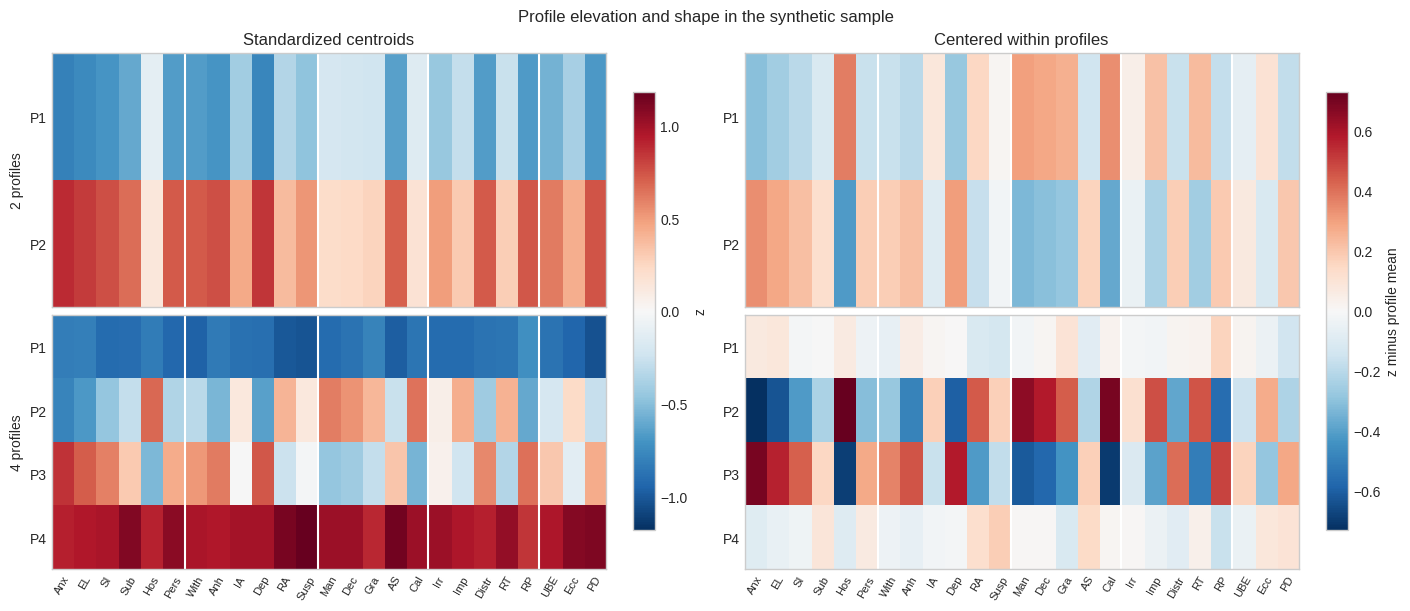

In [6]:
profiles = {k: summaries[k][1:3] for k in (2, 4)}
fig = plot_profiles(profiles, DOMAINS)
fig.savefig(figure_dir / "profile-elevation-and-shape.png", dpi=170, bbox_inches="tight")
plt.show()

## 9. Two-profile solution

Two components summarize a broad lower-to-higher elevation gradient. The centered map still shows some relative contrasts. The table reports estimated mixture weights, modal counts and the mean and 10th percentile of posterior probabilities among the records assigned to each profile.

In [7]:
display(summaries[2][0].round(3))
print(f"Elevation share: {summaries[2][3]:.1%} · Minimum seed-pair ARI: {metrics.loc[2, 'min_ARI']:.3f}")

,n_modal,modal_pct,weight_pct,posterior_mean,posterior_p10,elevation_z
P1,523,52.3,52.331,1.000,1.0,-0.496
P2,477,47.7,47.669,0.999,1.0,0.545


Elevation share: 84.5% · Minimum seed-pair ARI: 1.000


## 10. Four-profile solution

The main line chart shows the 25 fitted facet means for each profile. The five labeled domains organize the axis, and each point represents a separate facet. The horizontal zero line marks the synthetic sample mean for each facet. The centered view in Section 8 helps distinguish relative facet highs and lows from overall elevation. Modal proportions and estimated mixture weights are shown alongside the two-profile solution.

,n_modal,modal_pct,weight_pct,posterior_mean,posterior_p10,elevation_z
P1,277,27.7,27.699,1.0,1.0,-0.894
P2,247,24.7,24.699,1.0,1.0,-0.046
P3,258,25.8,25.807,1.0,1.0,0.156
P4,218,21.8,21.795,1.0,1.0,1.003


Elevation share: 80.9% · Minimum seed-pair ARI: 1.000


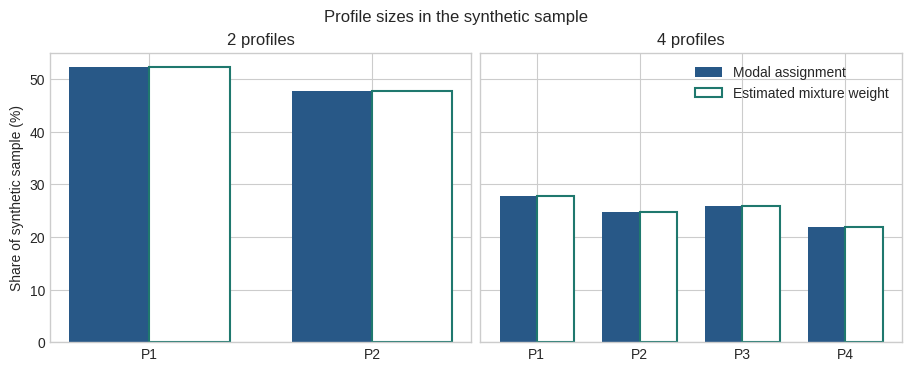

In [8]:
display(summaries[4][0].round(3))
print(f"Elevation share: {summaries[4][3]:.1%} · Minimum seed-pair ARI: {metrics.loc[4, 'min_ARI']:.3f}")

fig = plot_sizes({k: summaries[k][0] for k in (2, 4)})
fig.savefig(figure_dir / "profile-sizes.png", dpi=170, bbox_inches="tight")
plt.show()

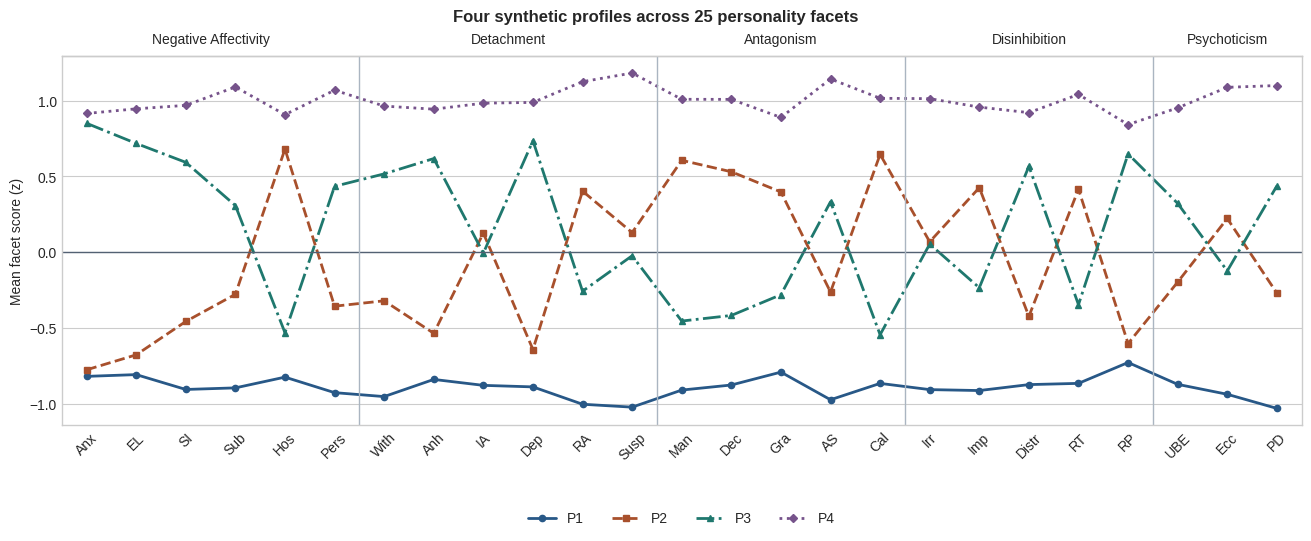

In [9]:
fig = plot_profile_lines(profiles[4][0], DOMAINS)
fig.savefig(figure_dir / "four-profile-facets.png", dpi=170, bbox_inches="tight")
plt.show()

### Interpretation of the four-profile solution

#### Methodological interpretation

Four profiles had the lowest AIC and BIC among the one- to eight-component fits. Both criteria balance fit and complexity, with different penalties. All five converged seed runs gave identical modal assignments (minimum pairwise adjusted Rand index = 1.00). The smallest and largest modal groups contained 218 and 277 of the 1,000 synthetic observations. Mean posterior probabilities for the assigned profile were above 0.999 in all four groups. Classification certainty describes the fitted mixture, while seed agreement describes the reproducibility of assignments across optimization runs on this sample. Interpreting the criteria alongside these quantities and the fitted profiles shows what the four-component solution adds to the simpler two-component summary.

General elevation accounted for about 85% of weighted between-centroid variation at two components and 81% at four. Centering each profile reveals differences in relative facet levels, especially between the middle profiles. At six components, the in-sample log-likelihood rose from −26,592.90 to −26,499.74, while the minimum seed-pair ARI fell to 0.75 and the smallest group contained 35 observations. Extra components can partition the same regions of the score distribution in different ways across runs.

#### Substantive interpretation

Overall elevation is the average of the 25 fitted standardized facet means. Relative highs and lows below are compared with each profile's own elevation. They are easiest to see in the centered heatmap.

| Profile | Overall elevation | Facet configuration |
|---|---:|---|
| **P1 · Lower overall elevation** | −0.89 z | The facets are consistently below the synthetic sample mean. Shape differences are modest. Within Disinhibition, Rigid Perfectionism is relatively higher than Impulsivity. Within Psychoticism, Perceptual Dysregulation is relatively lower than Unusual Beliefs and Experiences. |
| **P2 · Intermediate elevation** | −0.05 z | Hostility is relatively high, while Anxiousness and Emotional Lability are low within Negative Affectivity. Callousness and Manipulativeness are relatively high within Antagonism, while Attention Seeking is low. Risk Taking and Impulsivity are relatively high, and Rigid Perfectionism and Distractibility are low within Disinhibition. |
| **P3 · Intermediate elevation** | +0.16 z | Anxiousness and Emotional Lability are relatively high, while Hostility is low. Within Detachment, Depressivity and Anhedonia are relatively high and Restricted Affectivity is low. Attention Seeking is relatively higher than Callousness and Manipulativeness. The configuration contrasts with P2 despite their similar overall elevation. |
| **P4 · Higher overall elevation** | +1.00 z | The facets are consistently above the synthetic sample mean. Shape differences are modest. Within Detachment, Suspiciousness and Restricted Affectivity are relatively higher than Anhedonia. Within Antagonism, Attention Seeking is relatively higher than Grandiosity. |

#### Scope of the demonstration

The four components and their facet contrasts were specified in the simulation. These descriptions summarize fitted patterns in fictional continuous scores. They provide no empirical evidence about personality or clinical classifications.

## 11. Why more profiles are not always better

The six-component fit increases in-sample log-likelihood relative to four. Its AIC and BIC are higher, its smallest group is smaller, and its assignments vary more across seeds. This comparison shows why raw fit, penalized fit and stable assignments answer different questions.

In [10]:
display(metrics.loc[[2, 4, 6], ["log_likelihood", "AIC", "BIC", "relative_entropy",
                                 "min_modal_n", "converged_seeds", "median_ARI", "min_ARI"]].round(3))

,log_likelihood,AIC,BIC,relative_entropy,min_modal_n,converged_seeds,median_ARI,min_ARI
k,,,,,,,,
2,-30609.324,61420.648,61916.331,0.996,477,5,1.000,1.000
4,-26592.897,53591.794,54588.068,1.000,218,5,1.000,1.000
6,-26499.741,53609.483,55106.348,0.957,35,5,0.815,0.753


## 12. Limitations

The generator specifies four components and assumes independent Gaussian noise within them. The results depend on that design and the fixed seed. The continuous scores lack items, actual response scales and a scoring key. Seed agreement tests optimization on one dataset. Stability across samples and predictive performance would require separate validation. Psychological interpretation of real data would require evidence about measurement, sampling and the assumptions of the mixture.

## 13. Takeaways

Two profiles are a concise description of broad elevation. Four reveal the designed contrast in relative shape and are stable across the tested seeds. Six improve raw in-sample fit and produce less stable assignments. A defensible interpretation considers fit, parsimony, group sizes, posterior certainty and stability alongside the shape of the profiles.